# E-Commerce Sales & Customer Analytics

## Project Overview

This project analyzes e-commerce transaction data using SQL and Python to identify revenue trends, product performance, customer purchasing behavior, and geographic sales patterns.

The cleaned transaction data was organized into a relational H2 database consisting of customers, orders, order items, and products. SQL was then used to perform business-focused analysis, while Python and Matplotlib were used to visualize key findings.

## Project Objectives

- Analyze monthly revenue trends
- Identify top-selling products
- Analyze revenue by country
- Examine customer purchasing behavior
- Identify high-value customers
- Demonstrate SQL techniques including joins, aggregations, CTEs, subqueries, and window functions

# 1. Data Preparation and Cleaning

## 1.1 Load Dataset

The Online Retail dataset contains transaction-level information, including invoice numbers, products, quantities, prices, customer IDs, and countries.

In [3]:
import pandas as pd

df = pd.read_excel("Online Retail.xlsx")

df.head()



,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


## 1.2 Initial Data Inspection

In [7]:
df.shape

(541909, 8)

I checked the dataset for duplicate records to ensure that the same transaction was not recorded more than once.

In [8]:
df.duplicated().sum()

np.int64(5268)

## Inspect Duplicate Records

I inspected the duplicate records to determine whether they represent repeated transactions or exact duplicate entries.

In [9]:
duplicates = df[df.duplicated(keep=False)]

duplicates.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


## 1.3 Remove Duplicate Records

I removed exact duplicate records to prevent repeated transactions from affecting the analysis.

In [11]:
df = df.drop_duplicates()

In [12]:
df.shape

(536641, 8)

## 1.4 Check for Missing Values

I checked the dataset for missing values to identify columns that require additional cleaning before analysis.

In [14]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

## 1.5 Handle Missing Customer IDs

Transactions without a CustomerID cannot be reliably linked to a customer, so I removed these records from the analysis. This also removed the remaining rows with missing product descriptions.

In [15]:
df = df.dropna(subset=["CustomerID"])

In [16]:
df.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

## 1.6 Check for Invalid Values

I checked the Quantity and UnitPrice columns for zero or negative values that could affect the sales analysis.

In [17]:
(df["Quantity"] <= 0).sum()

np.int64(8872)

In [18]:
(df["UnitPrice"] <= 0).sum()

np.int64(40)

# Check for Canceled Transactions

I checked for canceled invoices because canceled transactions should not be treated as normal sales in the revenue analysis.

In [19]:
df["InvoiceNo"].astype(str).str.startswith("C").sum()

np.int64(8872)

## 1.7 Verify Canceled Transactions

I verified whether invoices beginning with “C” correspond to transactions with negative quantities.

In [20]:
df[df["InvoiceNo"].astype(str).str.startswith("C")]["Quantity"].value_counts().head()

Quantity
-1     3828
-2     1326
-3      576
-12     517
-6      468
Name: count, dtype: int64

### Validation
In the Online Retail dataset, invoice numbers beginning with “C” represent canceled transactions. I verified this by checking the quantities for these invoices, which were negative. Therefore, I excluded these transactions from the normal sales analysis.

## 1.8 Remove Canceled Transactions

In [21]:
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

In [22]:
df.shape

(392732, 8)

## 1.9 Final Check for Invalid Values

I checked whether any zero or negative quantities remained after removing canceled transactions.

In [23]:
(df["Quantity"] <= 0).sum()

np.int64(0)

In [24]:
(df["UnitPrice"] <= 0).sum()

np.int64(40)

In [25]:
df[df["UnitPrice"] <= 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647.0,Germany
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,2010-12-16 14:36:00,0.0,16560.0,United Kingdom
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,2010-12-21 13:45:00,0.0,14911.0,EIRE
47068,540372,22090,PAPER BUNTING RETROSPOT,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,2011-01-13 15:10:00,0.0,15107.0,United Kingdom
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,2011-02-10 13:08:00,0.0,17560.0,United Kingdom
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,2011-03-23 10:25:00,0.0,13239.0,United Kingdom
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,2011-03-30 12:45:00,0.0,13113.0,United Kingdom
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,2011-04-04 14:42:00,0.0,14410.0,United Kingdom


## 1.10 Remove Zero-Priced Transactions

I found 40 transactions with a UnitPrice of 0. These records contain product quantities but no sales price, so I excluded them from the revenue analysis because a valid positive unit price is required to calculate sales revenue.

In [26]:
df = df[df["UnitPrice"] > 0]

In [27]:
df.shape

(392692, 8)

## 1.11 Final Data Quality Check

I performed a final check to confirm that the cleaned dataset contains no missing values or invalid quantities and that the remaining unit prices are positive.

In [28]:
df.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [29]:
(df["Quantity"] <= 0).sum(), (df["UnitPrice"] <= 0).sum()

(np.int64(0), np.int64(0))

### 2.1 Connect to H2 Database

The cleaned transaction data was loaded into an H2 relational database using JayDeBeApi and JDBC.

In [35]:
!pip install JayDeBeApi

In [37]:
import jaydebeapi

In [38]:
import os

h2_jar = r"C:\Program Files (x86)\H2\bin\h2-2.5.250.jar"

print(os.path.exists(h2_jar))

True


In [40]:
import shutil
import os

print("Java:", shutil.which("java"))
print("JAVA_HOME:", os.environ.get("JAVA_HOME"))

Java: None
JAVA_HOME: None


In [41]:
import os

os.environ["JAVA_HOME"] = r"C:\Program Files\Eclipse Adoptium\jdk-21.0.12.101-hotspot"

os.environ["PATH"] = (
    os.path.join(os.environ["JAVA_HOME"], "bin")
    + os.pathsep
    + os.environ["PATH"]
)

In [42]:
import shutil
import jpype

print("Java:", shutil.which("java"))
print("JVM:", jpype.getDefaultJVMPath())

Java: C:\Program Files\Eclipse Adoptium\jdk-21.0.12.101-hotspot\bin\java.EXE
JVM: C:\Program Files\Eclipse Adoptium\jdk-21.0.12.101-hotspot\bin\server\jvm.dll


In [50]:
import jaydebeapi

h2_jar = r"C:\Program Files (x86)\H2\bin\h2-2.5.250.jar"

conn = jaydebeapi.connect(
    "org.h2.Driver",
    "jdbc:h2:file:C:/Users/moham/ecommerce",
    ["sa", ""],
    h2_jar
)

print("Connected to H2!")

Connected to H2!


## 2.2 Verify Database Tables

In [51]:
cursor = conn.cursor()
cursor.execute("SHOW TABLES")
print(cursor.fetchall())

[('CUSTOMERS', 'PUBLIC'), ('ORDERS', 'PUBLIC'), ('ORDER_ITEMS', 'PUBLIC'), ('PRODUCTS', 'PUBLIC')]


## 2.3 Verify Database Schema

In [53]:
cursor.execute("""
SELECT TABLE_NAME, COLUMN_NAME, DATA_TYPE, IS_NULLABLE
FROM INFORMATION_SCHEMA.COLUMNS
WHERE TABLE_NAME IN ('CUSTOMERS', 'ORDERS', 'ORDER_ITEMS', 'PRODUCTS')
ORDER BY TABLE_NAME, ORDINAL_POSITION
""")

for row in cursor.fetchall():
    print(row)

('CUSTOMERS', 'CUSTOMER_ID', 'INTEGER', 'NO')
('CUSTOMERS', 'COUNTRY', 'CHARACTER VARYING', 'YES')
('ORDERS', 'ORDER_ID', 'INTEGER', 'NO')
('ORDERS', 'CUSTOMER_ID', 'INTEGER', 'YES')
('ORDERS', 'INVOICE_DATE', 'TIMESTAMP', 'YES')
('ORDER_ITEMS', 'ORDER_ITEM_ID', 'INTEGER', 'NO')
('ORDER_ITEMS', 'ORDER_ID', 'INTEGER', 'YES')
('ORDER_ITEMS', 'PRODUCT_ID', 'INTEGER', 'YES')
('ORDER_ITEMS', 'QUANTITY', 'INTEGER', 'YES')
('ORDER_ITEMS', 'UNIT_PRICE', 'NUMERIC', 'YES')
('PRODUCTS', 'PRODUCT_ID', 'INTEGER', 'NO')
('PRODUCTS', 'PRODUCT_CODE', 'CHARACTER VARYING', 'YES')
('PRODUCTS', 'DESCRIPTION', 'CHARACTER VARYING', 'YES')
('PRODUCTS', 'UNIT_PRICE', 'NUMERIC', 'YES')


# 2.4 Verify Cleaned Dataset

In [54]:
print(df.shape)
print(df.columns.tolist())
df.head()

(392692, 8)
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Before loading the data into the relational tables, I verified that the cleaned dataset contains 392,692 transaction records across 8 columns.

## 2.5 Load Data into H2 Tables
The cleaned transaction data was transformed into separate DataFrames corresponding to the relational database tables. Customer, product, order, and order-item data were prepared separately before being inserted into H2.

## 2.5.1 Prepare Customer Data

In [56]:
customers_df = (
    df[["CustomerID", "Country"]]
    .drop_duplicates(subset=["CustomerID"])
    .copy()
)

print(customers_df.shape)
customers_df.head()

(4338, 2)


,CustomerID,Country
0,17850.0,United Kingdom
9,13047.0,United Kingdom
26,12583.0,France
46,13748.0,United Kingdom
65,15100.0,United Kingdom


### 2.5.2 Prepare Product Data

In [57]:
products_df = (
    df.groupby("StockCode", as_index=False)
      .agg({
          "Description": "first",
          "UnitPrice": "mean"
      })
)

print(products_df.shape)
products_df.head()

(3665, 3)


,StockCode,Description,UnitPrice
0,10002,INFLATABLE POLITICAL GLOBE,0.850000
1,10080,GROOVY CACTUS INFLATABLE,0.411905
2,10120,DOGGY RUBBER,0.210000
3,10125,MINI FUNKY DESIGN TAPES,0.781746
4,10133,COLOURING PENCILS BROWN TUBE,0.529262


## 2.5.3 Prepare Order Data

In [58]:
orders_df = (
    df[["InvoiceNo", "CustomerID", "InvoiceDate"]]
    .drop_duplicates(subset=["InvoiceNo"])
    .copy()
)

print(orders_df.shape)
orders_df.head()

(18532, 3)


,InvoiceNo,CustomerID,InvoiceDate
0,536365,17850.0,2010-12-01 08:26:00
7,536366,17850.0,2010-12-01 08:28:00
9,536367,13047.0,2010-12-01 08:34:00
21,536368,13047.0,2010-12-01 08:34:00
25,536369,13047.0,2010-12-01 08:35:00


### 2.5.4 Prepare Order Item Data

In [59]:
order_items_df = df[
    ["InvoiceNo", "StockCode", "Quantity", "UnitPrice"]
].copy()

print(order_items_df.shape)
order_items_df.head()

(392692, 4)


,InvoiceNo,StockCode,Quantity,UnitPrice
0,536365,85123A,6,2.55
1,536365,71053,6,3.39
2,536365,84406B,8,2.75
3,536365,84029G,6,3.39
4,536365,84029E,6,3.39


## 2.5.5 Insert Customer Data

In [60]:
customer_rows = list(
    customers_df[["CustomerID", "Country"]]
    .itertuples(index=False, name=None)
)

cursor.executemany(
    """
    INSERT INTO CUSTOMERS (CUSTOMER_ID, COUNTRY)
    VALUES (?, ?)
    """,
    customer_rows
)

conn.commit()

print(f"Inserted {len(customer_rows):,} customers.")

Inserted 4,338 customers.


## 2.5.5 Insert Customer Data

In [62]:
conn.rollback()

In [63]:
products_df = products_df.reset_index(drop=True)
products_df["ProductID"] = products_df.index + 1

products_df.head()

,StockCode,Description,UnitPrice,ProductID
0,10002,INFLATABLE POLITICAL GLOBE,0.850000,1
1,10080,GROOVY CACTUS INFLATABLE,0.411905,2
2,10120,DOGGY RUBBER,0.210000,3
3,10125,MINI FUNKY DESIGN TAPES,0.781746,4
4,10133,COLOURING PENCILS BROWN TUBE,0.529262,5


In [64]:
product_rows = list(
    products_df[
        ["ProductID", "StockCode", "Description", "UnitPrice"]
    ].itertuples(index=False, name=None)
)

cursor.executemany(
    """
    INSERT INTO PRODUCTS
        (PRODUCT_ID, PRODUCT_CODE, DESCRIPTION, UNIT_PRICE)
    VALUES (?, ?, ?, ?)
    """,
    product_rows
)

conn.commit()

print(f"Inserted {len(product_rows):,} products.")

Inserted 3,665 products.


### 2.5.6 Insert Order Item Data

In [70]:
orders_df["InvoiceDate"] = orders_df["InvoiceDate"].dt.strftime("%Y-%m-%d %H:%M:%S")

In [71]:
order_rows = list(
    orders_df[
        ["OrderID", "CustomerID", "InvoiceDate"]
    ].itertuples(index=False, name=None)
)

print(order_rows[:3])

[(1, 17850.0, '2010-12-01 08:26:00'), (2, 17850.0, '2010-12-01 08:28:00'), (3, 13047.0, '2010-12-01 08:34:00')]


In [72]:
cursor.executemany(
    """
    INSERT INTO ORDERS
        (ORDER_ID, CUSTOMER_ID, INVOICE_DATE)
    VALUES (?, ?, ?)
    """,
    order_rows
)

conn.commit()

print(f"Inserted {len(order_rows):,} orders.")

Inserted 18,532 orders.


## 2.5.6 Map Order and Product IDs

In [73]:
# Create lookup dictionaries
order_id_map = dict(
    zip(orders_df["InvoiceNo"], orders_df["OrderID"])
)

product_id_map = dict(
    zip(products_df["StockCode"], products_df["ProductID"])
)

# Map the IDs into the order items
order_items_df["OrderID"] = order_items_df["InvoiceNo"].map(order_id_map)
order_items_df["ProductID"] = order_items_df["StockCode"].map(product_id_map)

print(order_items_df[["InvoiceNo", "StockCode", "OrderID", "ProductID"]].head())

  InvoiceNo StockCode  OrderID  ProductID
0    536365    85123A        1       3350
1    536365     71053        1       2426
2    536365    84406B        1       3115
3    536365    84029G        1       3085
4    536365    84029E        1       3084


In [74]:
print("Missing Order IDs:", order_items_df["OrderID"].isna().sum())
print("Missing Product IDs:", order_items_df["ProductID"].isna().sum())

Missing Order IDs: 0
Missing Product IDs: 0


### 2.5.7 Prepare Order Item Records

In [75]:
order_item_rows = list(
    order_items_df[
        ["OrderID", "ProductID", "Quantity", "UnitPrice"]
    ].itertuples(index=False, name=None)
)

print(f"Rows ready to insert: {len(order_item_rows):,}")

Rows ready to insert: 392,692


### 2.5.8 Load Order Items into H2

In [77]:
conn.rollback()

In [78]:
order_items_df = order_items_df.reset_index(drop=True)
order_items_df["OrderItemID"] = order_items_df.index + 1

print(order_items_df[["OrderItemID", "OrderID", "ProductID", "Quantity", "UnitPrice"]].head())

   OrderItemID  OrderID  ProductID  Quantity  UnitPrice
0            1        1       3350         6       2.55
1            2        1       2426         6       3.39
2            3        1       3115         8       2.75
3            4        1       3085         6       3.39
4            5        1       3084         6       3.39


In [79]:
order_item_rows = list(
    order_items_df[
        ["OrderItemID", "OrderID", "ProductID", "Quantity", "UnitPrice"]
    ].itertuples(index=False, name=None)
)

print(f"Rows ready to insert: {len(order_item_rows):,}")

Rows ready to insert: 392,692


In [80]:
batch_size = 5000

insert_sql = """
INSERT INTO ORDER_ITEMS
    (ORDER_ITEM_ID, ORDER_ID, PRODUCT_ID, QUANTITY, UNIT_PRICE)
VALUES (?, ?, ?, ?, ?)
"""

for start in range(0, len(order_item_rows), batch_size):
    batch = order_item_rows[start:start + batch_size]
    
    cursor.executemany(insert_sql, batch)
    conn.commit()
    
    print(
        f"Inserted {min(start + batch_size, len(order_item_rows)):,} "
        f"/ {len(order_item_rows):,}"
    )

Inserted 5,000 / 392,692
Inserted 10,000 / 392,692
Inserted 15,000 / 392,692
Inserted 20,000 / 392,692
Inserted 25,000 / 392,692
Inserted 30,000 / 392,692
Inserted 35,000 / 392,692
Inserted 40,000 / 392,692
Inserted 45,000 / 392,692
Inserted 50,000 / 392,692
Inserted 55,000 / 392,692
Inserted 60,000 / 392,692
Inserted 65,000 / 392,692
Inserted 70,000 / 392,692
Inserted 75,000 / 392,692
Inserted 80,000 / 392,692
Inserted 85,000 / 392,692
Inserted 90,000 / 392,692
Inserted 95,000 / 392,692
Inserted 100,000 / 392,692
Inserted 105,000 / 392,692
Inserted 110,000 / 392,692
Inserted 115,000 / 392,692
Inserted 120,000 / 392,692
Inserted 125,000 / 392,692
Inserted 130,000 / 392,692
Inserted 135,000 / 392,692
Inserted 140,000 / 392,692
Inserted 145,000 / 392,692
Inserted 150,000 / 392,692
Inserted 155,000 / 392,692
Inserted 160,000 / 392,692
Inserted 165,000 / 392,692
Inserted 170,000 / 392,692
Inserted 175,000 / 392,692
Inserted 180,000 / 392,692
Inserted 185,000 / 392,692
Inserted 190,000 / 39

## 2.6 Verify H2 Database

In [82]:
cursor.execute("""
SELECT
    (SELECT COUNT(*) FROM CUSTOMERS) AS customers,
    (SELECT COUNT(*) FROM PRODUCTS) AS products,
    (SELECT COUNT(*) FROM ORDERS) AS orders,
    (SELECT COUNT(*) FROM ORDER_ITEMS) AS order_items
""")

print(cursor.fetchall())

[(4338, 3665, 18532, 392692)]


I verified the record counts in each table to confirm that the cleaned data was successfully loaded into the H2 database.

# 3. SQL Analysis

## 3.1 Sales Performance Analysis

### Monthly Revenue

In [85]:
cursor.execute("""
SELECT
    YEAR(o.INVOICE_DATE) AS ORDER_YEAR,
    MONTH(o.INVOICE_DATE) AS ORDER_MONTH,
    SUM(oi.QUANTITY * oi.UNIT_PRICE) AS REVENUE
FROM ORDERS o
JOIN ORDER_ITEMS oi
    ON o.ORDER_ID = oi.ORDER_ID
GROUP BY YEAR(o.INVOICE_DATE), MONTH(o.INVOICE_DATE)
ORDER BY YEAR(o.INVOICE_DATE), MONTH(o.INVOICE_DATE)
""")

monthly_sales = cursor.fetchall()

for row in monthly_sales:
    print(row)

(2010, 12, 570422.73)
(2011, 1, 568101.31)
(2011, 2, 446084.92)
(2011, 3, 594081.76)
(2011, 4, 468374.33)
(2011, 5, 677355.15)
(2011, 6, 660046.05)
(2011, 7, 598962.9)
(2011, 8, 644051.04)
(2011, 9, 950690.2)
(2011, 10, 1035642.45)
(2011, 11, 1156205.61)
(2011, 12, 517190.44)


## 3.2 Revenue by Country

In [86]:
cursor.execute("""
SELECT
    c.COUNTRY,
    SUM(oi.QUANTITY * oi.UNIT_PRICE) AS REVENUE
FROM CUSTOMERS c
JOIN ORDERS o
    ON c.CUSTOMER_ID = o.CUSTOMER_ID
JOIN ORDER_ITEMS oi
    ON o.ORDER_ID = oi.ORDER_ID
GROUP BY c.COUNTRY
ORDER BY REVENUE DESC
""")

country_sales = cursor.fetchall()

for row in country_sales:
    print(row)

('United Kingdom', 7285024.64)
('Netherlands', 285446.34)
('EIRE', 265262.46)
('Germany', 228678.4)
('France', 208934.31)
('Australia', 139843.95)
('Spain', 60354.3)
('Switzerland', 56419.29)
('Belgium', 41551.26)
('Sweden', 38367.83)
('Japan', 37416.37)
('Norway', 36165.44)
('Portugal', 33375.84)
('Finland', 22546.08)
('Singapore', 21279.29)
('Channel Islands', 20440.54)
('Denmark', 18501.92)
('Italy', 17483.24)
('Cyprus', 14155.31)
('Austria', 9483.5)
('Poland', 7334.65)
('Israel', 7215.84)
('Greece', 4760.52)
('Iceland', 4310.0)
('Canada', 3666.38)
('USA', 3580.39)
('Malta', 2725.59)
('Unspecified', 2660.77)
('United Arab Emirates', 1902.28)
('Lebanon', 1693.88)
('Lithuania', 1661.06)
('European Community', 1300.25)
('Brazil', 1143.6)
('RSA', 1002.31)
('Czech Republic', 826.74)
('Bahrain', 548.4)
('Saudi Arabia', 145.92)


### Interpretation

This query calculates total revenue by country by joining the Customers, Orders, and Order Items tables. The results are grouped by country and sorted from highest to lowest revenue.

The United Kingdom generated the highest total revenue in the dataset, followed by the Netherlands and Ireland. This analysis helps identify the geographic markets that contributed the most to overall sales.

## 3.3 Top-Selling Products

In [88]:
cursor.execute("""
SELECT
    p.PRODUCT_CODE,
    p.DESCRIPTION,
    SUM(oi.QUANTITY) AS TOTAL_QUANTITY_SOLD,
    SUM(oi.QUANTITY * oi.UNIT_PRICE) AS REVENUE
FROM PRODUCTS p
JOIN ORDER_ITEMS oi
    ON p.PRODUCT_ID = oi.PRODUCT_ID
GROUP BY p.PRODUCT_CODE, p.DESCRIPTION
ORDER BY TOTAL_QUANTITY_SOLD DESC
LIMIT 10
""")

top_products = cursor.fetchall()

for row in top_products:
    print(row)

('23843', 'PAPER CRAFT , LITTLE BIRDIE', 80995, 168469.6)
('23166', 'MEDIUM CERAMIC TOP STORAGE JAR', 77916, 81416.73)
('84077', 'WORLD WAR 2 GLIDERS ASSTD DESIGNS', 54319, 13558.41)
('22197', 'SMALL POPCORN HOLDER', 49160, 37206.88)
('85099B', 'JUMBO BAG RED RETROSPOT', 46078, 85040.54)
('85123A', 'WHITE HANGING HEART T-LIGHT HOLDER', 36763, 100547.45)
('84879', 'ASSORTED COLOUR BIRD ORNAMENT', 35263, 56413.03)
('21212', 'PACK OF 72 RETROSPOT CAKE CASES', 33670, 16381.88)
('23084', 'RABBIT NIGHT LIGHT', 27153, 51251.24)
('22492', 'MINI PAINT SET VINTAGE ', 26076, 16039.24)


### Interpretation

This query identifies the top 10 products by total quantity sold. It joins the Products and Order Items tables, then aggregates the quantity sold for each product.

The results show that Paper Craft, Little Birdie had the highest quantity sold, with 80,995 units, followed by Medium Ceramic Top Storage Jar with 77,916 units. The analysis helps identify products with the highest sales volume.

## 3.4 Average Order Value

In [90]:
cursor.execute("""
SELECT
    AVG(order_total) AS AVERAGE_ORDER_VALUE
FROM (
    SELECT
        o.ORDER_ID,
        SUM(oi.QUANTITY * oi.UNIT_PRICE) AS order_total
    FROM ORDERS o
    JOIN ORDER_ITEMS oi
        ON o.ORDER_ID = oi.ORDER_ID
    GROUP BY o.ORDER_ID
)
""")

average_order = cursor.fetchone()

print("Average Order Value:", average_order[0])

Average Order Value: 479.560160263328


### Interpretation

The average order value is approximately 479.56,  meaning the average customer order generated about $479.56 in revenue.

## 3.5 Customer Analysis

In [93]:
cursor.execute("""
SELECT
    CASE
        WHEN customer_order_count > 1 THEN 'Repeat Customer'
        ELSE 'One-Time Customer'
    END AS CUSTOMER_TYPE,
    COUNT(*) AS CUSTOMER_COUNT
FROM (
    SELECT
        c.CUSTOMER_ID,
        COUNT(o.ORDER_ID) AS customer_order_count
    FROM CUSTOMERS c
    LEFT JOIN ORDERS o
        ON c.CUSTOMER_ID = o.CUSTOMER_ID
    GROUP BY c.CUSTOMER_ID
)
GROUP BY
    CASE
        WHEN customer_order_count > 1 THEN 'Repeat Customer'
        ELSE 'One-Time Customer'
    END
ORDER BY CUSTOMER_COUNT DESC
""")

customer_types = cursor.fetchall()

for row in customer_types:
    print(row)

('Repeat Customer', 2845)
('One-Time Customer', 1493)


# Interpatation

The analysis shows that 2,845 of 4,338 customers (65.6%) were repeat customers, while 1,493 customers (34.4%) were one-time customers. Repeat customers therefore made up nearly two-thirds of the customer base during the period analyzed. This indicates that the business had a substantial level of customer retention, with a larger share of customers making multiple purchases rather than purchasing only once

## 3.6 Top Customers by Revenue

Customer revenue was calculated by joining Customers, Orders, and Order Items and summing the revenue generated by each customer. The results were sorted to identify the 10 highest-spending customers.

In [94]:
cursor.execute("""
SELECT
    c.CUSTOMER_ID,
    c.COUNTRY,
    SUM(oi.QUANTITY * oi.UNIT_PRICE) AS TOTAL_SPENDING
FROM CUSTOMERS c
JOIN ORDERS o
    ON c.CUSTOMER_ID = o.CUSTOMER_ID
JOIN ORDER_ITEMS oi
    ON o.ORDER_ID = oi.ORDER_ID
GROUP BY c.CUSTOMER_ID, c.COUNTRY
ORDER BY TOTAL_SPENDING DESC
LIMIT 10
""")

top_customers = cursor.fetchall()

for row in top_customers:
    print(row)

(14646, 'Netherlands', 280206.02)
(18102, 'United Kingdom', 259657.3)
(17450, 'United Kingdom', 194390.79)
(16446, 'United Kingdom', 168472.5)
(14911, 'EIRE', 143711.17)
(12415, 'Australia', 124914.53)
(14156, 'EIRE', 117210.08)
(17511, 'United Kingdom', 91062.38)
(16029, 'United Kingdom', 80850.84)
(12346, 'United Kingdom', 77183.6)


### Interpretation

The analysis identifies the 10 customers with the highest total spending in the dataset. Customer 14646, from the Netherlands, had the highest total spending at approximately 280,206, followed by Customer 18102 from the United Kingdom at approximately **$259,657**.

The results also show that most of the highest-spending customers were from the United Kingdom, with additional high-value customers from the Netherlands, Ireland, and Australia. This analysis helps identify customers who contributed substantially to overall revenue.

## 3.7 Top Customers by Country Using RANK()

Customer spending was ranked separately within each country using the RANK() window function. This allows high-value customers to be compared within their respective geographic markets.

In [99]:
cursor.execute("""
WITH customer_revenue AS (
    SELECT
        c.COUNTRY,
        c.CUSTOMER_ID,
        SUM(oi.QUANTITY * oi.UNIT_PRICE) AS TOTAL_SPENDING
    FROM CUSTOMERS c
    JOIN ORDERS o
        ON c.CUSTOMER_ID = o.CUSTOMER_ID
    JOIN ORDER_ITEMS oi
        ON o.ORDER_ID = oi.ORDER_ID
    GROUP BY c.COUNTRY, c.CUSTOMER_ID
)

SELECT
    COUNTRY,
    CUSTOMER_ID,
    TOTAL_SPENDING,
    RANK() OVER (
        PARTITION BY COUNTRY
        ORDER BY TOTAL_SPENDING DESC
    ) AS CUSTOMER_RANK
FROM customer_revenue
ORDER BY COUNTRY, CUSTOMER_RANK
LIMIT 20
""")

ranked_customers = cursor.fetchall()

for row in ranked_customers:
    print(row)

('Australia', 12415, 124914.53, 1)
('Australia', 12431, 6419.95, 2)
('Australia', 12388, 2780.66, 3)
('Australia', 12424, 1760.96, 4)
('Australia', 12393, 1582.6, 5)
('Australia', 12434, 806.14, 6)
('Australia', 12422, 803.56, 7)
('Australia', 12386, 401.9, 8)
('Australia', 16321, 373.65, 9)
('Austria', 12360, 2662.06, 1)
('Austria', 12865, 1568.23, 2)
('Austria', 12818, 1542.08, 3)
('Austria', 12358, 1168.06, 4)
('Austria', 12374, 742.93, 5)
('Austria', 12453, 707.09, 6)
('Austria', 12414, 562.41, 7)
('Austria', 12373, 364.6, 8)
('Austria', 12817, 166.04, 9)
('Bahrain', 12355, 459.4, 1)
('Bahrain', 12353, 89.0, 2)


### Interpretation

This analysis ranks customers within each country based on their total spending. The `RANK()` window function assigns a ranking separately for each country, allowing high-value customers to be identified within their respective markets.

For example, Customer 12415 ranked first among Australian customers with approximately $124,915 in total spending. Customer 12360 ranked first among Austrian customers with approximately 2,662 in total spending.

This analysis can help identify the highest-value customers within individual geographic markets.

## 3.8 Month-over-Month Revenue Comparison

In [102]:
cursor.execute("""
WITH monthly_revenue AS (
    SELECT
        YEAR(o.INVOICE_DATE) AS ORDER_YEAR,
        MONTH(o.INVOICE_DATE) AS ORDER_MONTH,
        SUM(oi.QUANTITY * oi.UNIT_PRICE) AS REVENUE
    FROM ORDERS o
    JOIN ORDER_ITEMS oi
        ON o.ORDER_ID = oi.ORDER_ID
    GROUP BY
        YEAR(o.INVOICE_DATE),
        MONTH(o.INVOICE_DATE)
)

SELECT
    ORDER_YEAR,
    ORDER_MONTH,
    REVENUE,
    LAG(REVENUE) OVER (
        ORDER BY ORDER_YEAR, ORDER_MONTH
    ) AS PREVIOUS_MONTH_REVENUE
FROM monthly_revenue
ORDER BY ORDER_YEAR, ORDER_MONTH
""")

mom_revenue = cursor.fetchall()

for row in mom_revenue:
    print(row)

(2010, 12, 570422.73, None)
(2011, 1, 568101.31, 570422.73)
(2011, 2, 446084.92, 568101.31)
(2011, 3, 594081.76, 446084.92)
(2011, 4, 468374.33, 594081.76)
(2011, 5, 677355.15, 468374.33)
(2011, 6, 660046.05, 677355.15)
(2011, 7, 598962.9, 660046.05)
(2011, 8, 644051.04, 598962.9)
(2011, 9, 950690.2, 644051.04)
(2011, 10, 1035642.45, 950690.2)
(2011, 11, 1156205.61, 1035642.45)
(2011, 12, 517190.44, 1156205.61)


### Interpretation

This analysis uses the `LAG()` window function to compare each month's revenue with the previous month's revenue.

Revenue increased substantially during the second half of 2011, reaching approximately 1.16 million in November 2011, the highest monthly revenue in the results. December 2011 revenue then decreased to approximately $517,190.

The analysis demonstrates how window functions can be used to examine changes in revenue over time and compare current performance with the previous month.

## 3.9 Customer Order Frequency

In [105]:
cursor.execute("""
SELECT
    c.CUSTOMER_ID,
    c.COUNTRY,
    COUNT(o.ORDER_ID) AS ORDER_COUNT,
    SUM(oi.QUANTITY * oi.UNIT_PRICE) AS TOTAL_SPENDING
FROM CUSTOMERS c
JOIN ORDERS o
    ON c.CUSTOMER_ID = o.CUSTOMER_ID
JOIN ORDER_ITEMS oi
    ON o.ORDER_ID = oi.ORDER_ID
GROUP BY
    c.CUSTOMER_ID,
    c.COUNTRY
HAVING COUNT(o.ORDER_ID) > 1
ORDER BY ORDER_COUNT DESC
LIMIT 10
""")

order_frequency = cursor.fetchall()

for row in order_frequency:
    print(row)

(17841, 'United Kingdom', 7676, 40519.84)
(14911, 'EIRE', 5670, 143711.17)
(14096, 'United Kingdom', 5111, 65164.79)
(12748, 'United Kingdom', 4412, 33053.19)
(14606, 'United Kingdom', 2677, 12076.15)
(15311, 'United Kingdom', 2366, 60632.75)
(14646, 'Netherlands', 2076, 280206.02)
(13089, 'United Kingdom', 1814, 58762.08)
(13263, 'United Kingdom', 1667, 7436.93)
(14298, 'United Kingdom', 1637, 51527.3)


### Interpretation

This analysis identifies customers who placed more than one order and ranks them by order frequency. Customer 17841 from the United Kingdom had the highest number of orders, with 7,676 orders, while Customer 14911 from EIRE had 5,670 orders.

The results also show that some customers with a high number of orders generated substantial total spending. For example, Customer 14646 from the Netherlands placed 2,076 orders and generated approximately $280,206 in total spending.

This analysis helps identify customers with frequent purchasing activity and compare their order frequency with their overall spending.

# 4. Python Data Visualization

## 4.1 Monthly Revenue Trend

In [107]:
import pandas as pd
import matplotlib.pyplot as plt

monthly_df = pd.DataFrame(
    monthly_sales,
    columns=["Year", "Month", "Revenue"]
)

monthly_df["Date"] = pd.to_datetime(
    monthly_df["Year"].astype(str) + "-" +
    monthly_df["Month"].astype(str) + "-01"
)

monthly_df

,Year,Month,Revenue,Date
0,2010,12,570422.73,2010-12-01
1,2011,1,568101.31,2011-01-01
2,2011,2,446084.92,2011-02-01
3,2011,3,594081.76,2011-03-01
4,2011,4,468374.33,2011-04-01
5,2011,5,677355.15,2011-05-01
6,2011,6,660046.05,2011-06-01
7,2011,7,598962.90,2011-07-01
8,2011,8,644051.04,2011-08-01
9,2011,9,950690.20,2011-09-01


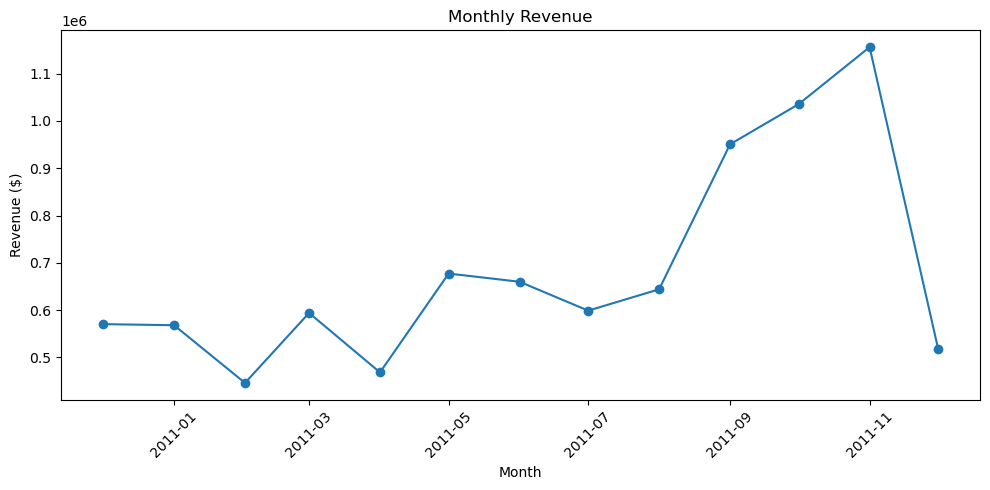

In [110]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_df["Date"],
    monthly_df["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Interpretation

Monthly revenue fluctuated throughout the period, with revenue generally increasing during the second half of 2011. Revenue reached its highest point in November 2011 at approximately 1.16 million, before decreasing to approximately **$517,190 in December 2011**.

The visualization makes the monthly revenue trend easier to identify and highlights the substantial increase in revenue during the later months of 2011.

## 4.2 Revenue by Country

In [111]:
country_df = pd.DataFrame(
    country_sales,
    columns=["Country", "Revenue"]
)

country_df.head(10)

,Country,Revenue
0,United Kingdom,7285024.64
1,Netherlands,285446.34
2,EIRE,265262.46
3,Germany,228678.40
4,France,208934.31
5,Australia,139843.95
6,Spain,60354.30
7,Switzerland,56419.29
8,Belgium,41551.26
9,Sweden,38367.83


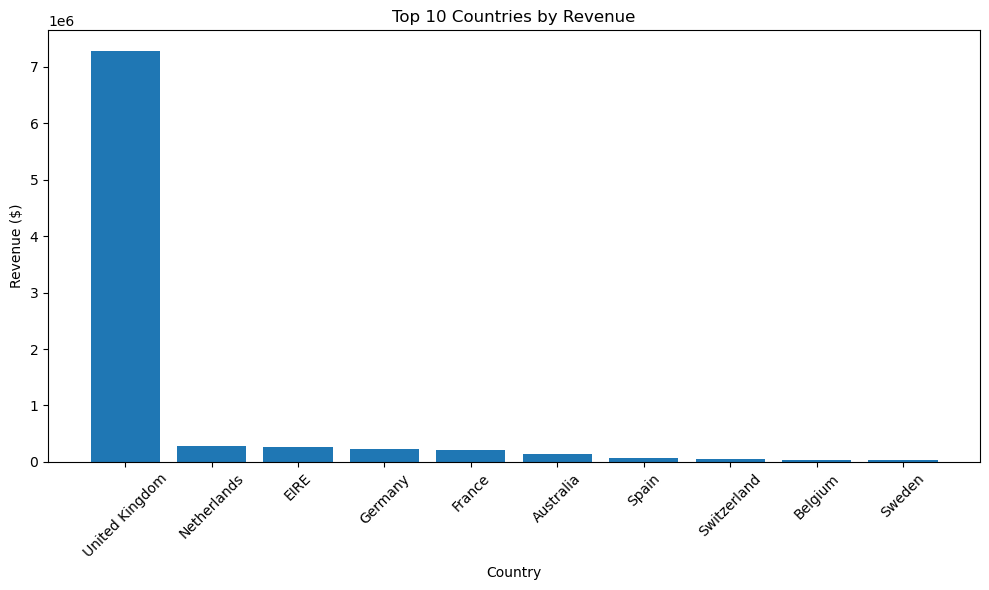

In [112]:
plt.figure(figsize=(10, 6))

top_10_countries = country_df.head(10)

plt.bar(
    top_10_countries["Country"],
    top_10_countries["Revenue"]
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Interpretation

The United Kingdom generated the highest revenue among the countries analyzed, followed by the Netherlands and EIRE. The United Kingdom's revenue was substantially higher than the other countries shown, indicating that it was the largest geographic contributor to revenue in the dataset.

The chart also shows that revenue was concentrated among a smaller number of countries, while the remaining countries contributed comparatively smaller amounts.

## 4.3 Top 10 Products by Quantity Sold

In [114]:
top_products_df = pd.DataFrame(
    top_products,
    columns=["Product Code", "Description", "Quantity Sold", "Revenue"]
)

top_products_df

,Product Code,Description,Quantity Sold,Revenue
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,77916,81416.73
2,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54319,13558.41
3,22197,SMALL POPCORN HOLDER,49160,37206.88
4,85099B,JUMBO BAG RED RETROSPOT,46078,85040.54
5,85123A,WHITE HANGING HEART T-LIGHT HOLDER,36763,100547.45
6,84879,ASSORTED COLOUR BIRD ORNAMENT,35263,56413.03
7,21212,PACK OF 72 RETROSPOT CAKE CASES,33670,16381.88
8,23084,RABBIT NIGHT LIGHT,27153,51251.24
9,22492,MINI PAINT SET VINTAGE,26076,16039.24


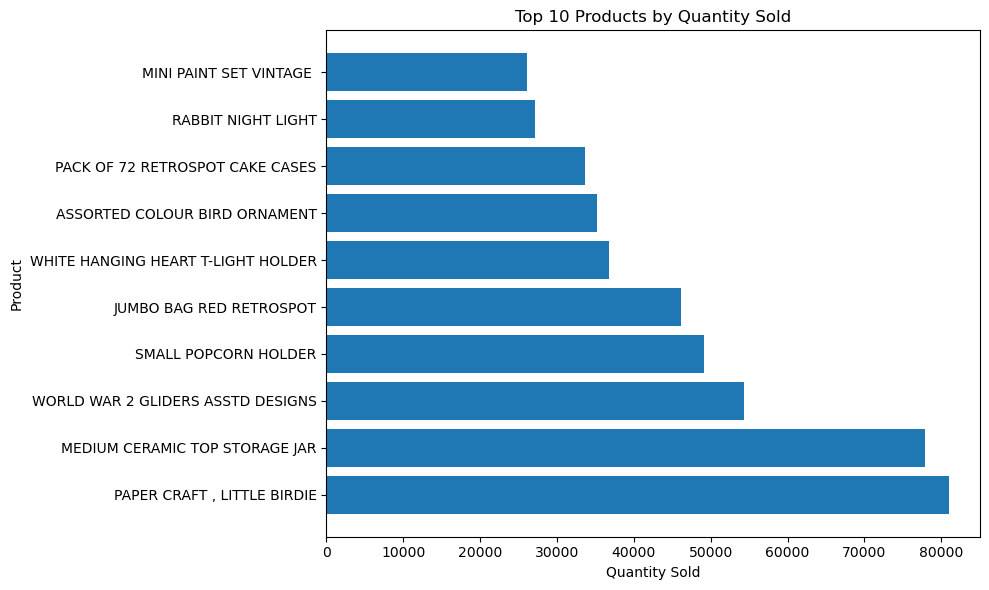

In [115]:
plt.figure(figsize=(10, 6))

top_10_products = top_products_df.head(10)

plt.barh(
    top_10_products["Description"],
    top_10_products["Quantity Sold"]
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

## 4.4 Customer Purchasing Behavior

In [117]:
customer_type_df = pd.DataFrame(
    customer_types,
    columns=["Customer Type", "Customer Count"]
)

customer_type_df

,Customer Type,Customer Count
0,Repeat Customer,2845
1,One-Time Customer,1493


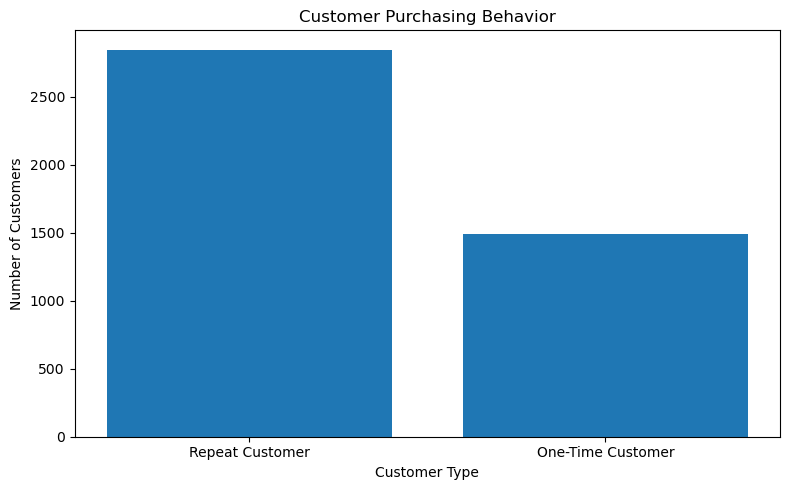

In [118]:
plt.figure(figsize=(8, 5))

plt.bar(
    customer_type_df["Customer Type"],
    customer_type_df["Customer Count"]
)

plt.title("Customer Purchasing Behavior")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Interpretation

The analysis shows that **2,845 customers were repeat customers**, compared with **1,493 one-time customers**. Repeat customers therefore represented approximately **65.6%** of the 4,338 customers analyzed.

This indicates that repeat purchasing was more common than one-time purchasing in the dataset. The visualization makes the difference in customer purchasing behavior easy to compare.

# 5. Key Business Findings

### 1. Revenue Trend

Monthly revenue increased substantially during the second half of 2011 and reached its highest point in **November 2011 at approximately $1.16 million**. Revenue then decreased to approximately **$517,190 in December 2011**.

### 2. Geographic Revenue

The **United Kingdom generated the highest total revenue** among the countries in the dataset, followed by the Netherlands and EIRE. Revenue was concentrated among a smaller number of geographic markets.

### 3. Product Sales

**Paper Craft, Little Birdie** had the highest quantity sold at approximately **81,000 units**, followed by **Medium Ceramic Top Storage Jar** at approximately **78,000 units**.

### 4. Customer Purchasing Behavior

The dataset contained **4,338 customers**, including **2,845 repeat customers (65.6%)** and **1,493 one-time customers (34.4%)**. Repeat purchasing was therefore more common than one-time purchasing.

### 5. Average Order Value

The average order value was approximately **$479.56**, providing a baseline measure of revenue generated per order.

### 6. High-Value Customers

Customer **14646 from the Netherlands** had the highest total spending at approximately **$280,206**, followed by Customer **18102 from the United Kingdom** at approximately **$259,657**.

## Project Conclusion

This project used SQL and Python to analyze e-commerce sales and customer purchasing behavior. A relational H2 database was created to organize customers, orders, products, and order items, containing more than 392,000 order-item records.

SQL queries were used to analyze revenue trends, geographic sales, product sales, customer purchasing behavior, and high-value customers. Advanced SQL techniques including CTEs, window functions, `RANK()`, and `LAG()` were also used to identify patterns in the data.

Python and Pandas were then used to transform SQL results into visualizations, making key trends and comparisons easier to interpret.

Overall, the project demonstrates the use of relational databases, SQL analytics, Python data processing, and data visualization to derive business insights from transactional data.

# 7. Technologies Used
- **Python** — Data cleaning, data preparation, and visualization
- **Pandas** — Data manipulation and transformation
- **SQL** — Data querying and analysis
- **H2 Database** — Relational database management
- **Matplotlib** — Data visualization
- **Jupyter Notebook** — Project development and analysis